In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex

#import csv

import numpy as np

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

import statsmodels.api as sm

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.impedance.analysis import Calculate_Impedance_RC_Model
from scientific_utils.impedance.analysis import Calculate_Impedance_RQ_Model
from scientific_utils.impedance.analysis import Fit_Z_Real_Imag_RCRCRCCPE
from scientific_utils.impedance.analysis import Fit_Z_Real_Imag_RQRQRQCPE
from scientific_utils.impedance.analysis import Fit_Z_Real_Imag_Phase_RQRQRQCPE
from scientific_utils.impedance.plotting import Matplotlib_Nyquist_Plot
from scientific_utils.impedance.plotting import Matplotlib_Compare_Model_And_Fit

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 10 # number of colour points taken from the colour gradient with equal distance
from scientific_utils.general.plotting import my_colormap
colormap = my_colormap.resampled(number_of_colorpoints) # was: plt.get_cmap('RdBu', number_of_colorpoints)
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list

In [6]:
########## Font settings for the PGF file (used in LaTeX) ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    "pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pgf.preamble": "\n".join([
        r"\usepackage[utf8x]{inputenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage[T1]{fontenc}",        # plots will be generated using this preamble
        ])
    }

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)
from scientific_utils.publication_plotly import my_color_scale # colours of the publication style

In [7]:
########## Packages for the fitting ##########
from numpy import exp, linspace, pi, random, sign, sin

from lmfit import Parameters, minimize, fit_report
from lmfit.printfuncs import report_fit

import numdifftools

import copy

In [8]:
########## Simulating a Impedance Spectrum ##########

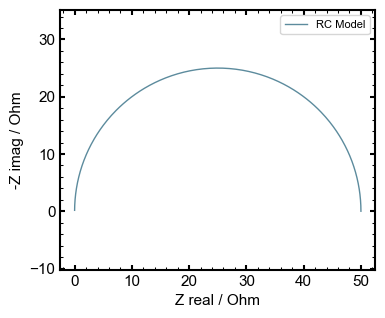

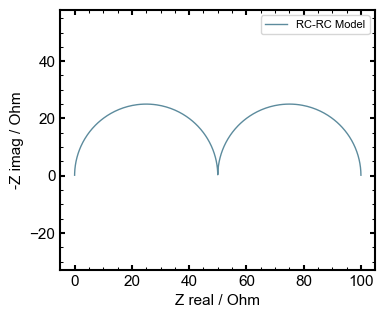

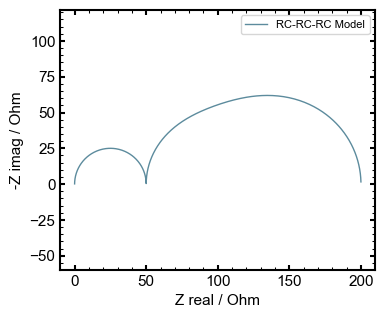

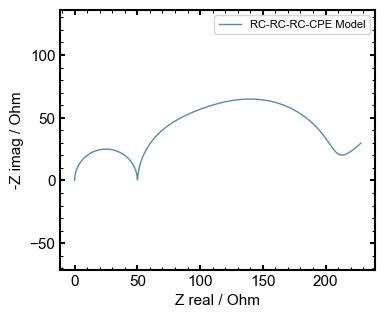

In [9]:
##### RC models (resistor and capacitor in parallel)
####### Plot with the defined functions

# Order of magnitude of the function variables
f = np.logspace(-2, 8, 1000)
R1 = 50
C1 = 10.0E-9
R2 = 50
C2 = 10.0E-4
R3 = 100
C3 = 2.2E-3
Q1 = 1.0E-1
n1 = 0.5   

# plot the RC model
label = 'RC Model'
ModelValuesRC = [R1, C1]

#BodePlotImpedance(f, ModelValuesRC, label)

#BodePlotPhaseAngle(f, ModelValuesRC, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRC, label, impedance_model=Calculate_Impedance_RC_Model)  

#############################################################

# plot the RCRC model
label = 'RC-RC Model'
ModelValuesRCRC = [R1, C1, R2, C2]

#BodePlotImpedance(f, ModelValuesRCRC, label)

#BodePlotPhaseAngle(f, ModelValuesRCRC, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRCRC, label, impedance_model=Calculate_Impedance_RC_Model)


#############################################################

# plot the RCRCRC model
label = 'RC-RC-RC Model'
ModelValuesRCRCRC = [R1, C1, R2, C2, R3, C3]

#BodePlotImpedance(f, ModelValuesRCRCRC, label)

#BodePlotPhaseAngle(f, ModelValuesRCRCRC, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRCRCRC, label, impedance_model=Calculate_Impedance_RC_Model)

#############################################################

# plot the RCRCRC model
label = 'RC-RC-RC-CPE Model'
ModelValuesRCRCRCCPE = [R1, C1, R2, C2, R3, C3, Q1, n1]

#BodePlotImpedance(f, ModelValuesRCRCRCCPE, label)

#BodePlotPhaseAngle(f, ModelValuesRCRCRCCPE, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRCRCRCCPE, label, impedance_model=Calculate_Impedance_RC_Model)

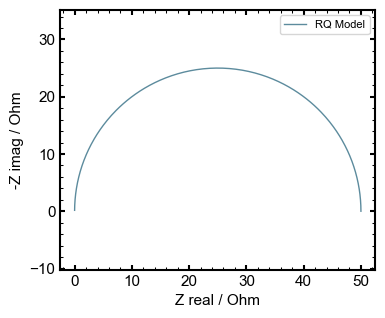

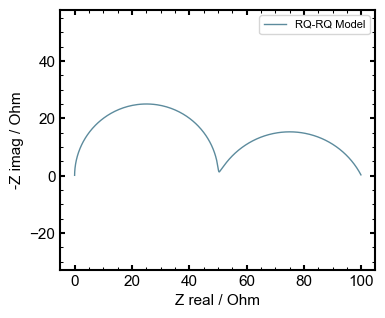

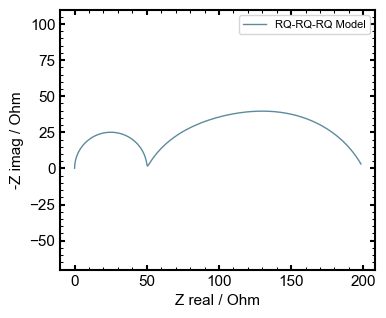

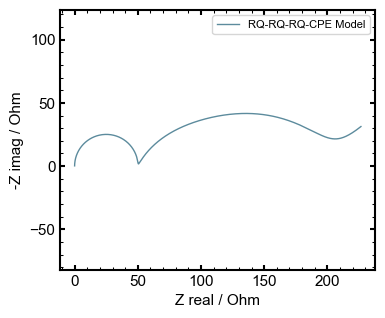

In [10]:
##### RQ models (resistor and constant phase element in parallel)
####### Plot with the defined functions

# Order of magnitude of the function variables
f = np.logspace(-2, 8, 1000)
R1 = 50
Q1 = 10.0E-9
n1 = 1.0

R2 = 50
Q2 = 10.0E-4
n2 = 0.7

R3 = 100
Q3 = 2.2E-3
n3 = 0.7

Q4 = 1.0E-1
n4 = 0.5   

# plot the RC model
label = 'RQ Model'
ModelValuesRQ = [R1, Q1, n1]

#BodePlotImpedance(f, ModelValuesRC, label)

#BodePlotPhaseAngle(f, ModelValuesRC, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRQ, label)  

#############################################################

# plot the RCRC model
label = 'RQ-RQ Model'
ModelValuesRQRQ = [R1, Q1, n1, R2, Q2, n2]

#BodePlotImpedance(f, ModelValuesRCRC, label)

#BodePlotPhaseAngle(f, ModelValuesRCRC, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRQRQ, label)


#############################################################

# plot the RCRCRC model
label = 'RQ-RQ-RQ Model'
ModelValuesRQRQRQ = [R1, Q1, n1, R2, Q2, n2, R3, Q3, n3]

#BodePlotImpedance(f, ModelValuesRCRCRC, label)

#BodePlotPhaseAngle(f, ModelValuesRCRCRC, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRQRQRQ, label)

#############################################################

# plot the RCRCRC model
label = 'RQ-RQ-RQ-CPE Model'
ModelValuesRQRQRQCPE = [R1, Q1, n1, R2, Q2, n2, R3, Q3, n3, Q4, n4]

#BodePlotImpedance(f, ModelValuesRCRCRCCPE, label)

#BodePlotPhaseAngle(f, ModelValuesRCRCRCCPE, label)
 
Matplotlib_Nyquist_Plot(f, ModelValuesRQRQRQCPE, label)

In [11]:
############################### Fit A: RC-RC-RC-CPE model, fitted to the real and imaginary part ####################

In [12]:
############ Define the Function for Fitting and the Parameters ##############

### Values of the function for simulating the data (only needed if the function is simulated again)
ModelParameters = Parameters() # Parameters is a function of the lmfit package
ModelParameters.add('R1', value=ModelValuesRCRCRCCPE[0]) # The above definde Parameters of the Model ('ModelValuesRCRCRCCPE') are also defiend for the Parameters() function
ModelParameters.add('C1', value=ModelValuesRCRCRCCPE[1])
ModelParameters.add('R2', value=ModelValuesRCRCRCCPE[2])
ModelParameters.add('C2', value=ModelValuesRCRCRCCPE[3])
ModelParameters.add('R3', value=ModelValuesRCRCRCCPE[4])
ModelParameters.add('C3', value=ModelValuesRCRCRCCPE[5])
ModelParameters.add('Q1', value=ModelValuesRCRCRCCPE[6])
ModelParameters.add('n1', value=ModelValuesRCRCRCCPE[7])

f = np.logspace(-2, 8, 1000)

Z_real_imag_measurement = np.append(Calculate_Impedance_RC_Model(f, ModelValuesRCRCRCCPE, PhaseAngle=False).real, Calculate_Impedance_RC_Model(f, ModelValuesRCRCRCCPE, PhaseAngle=False).imag)

#print(len(Z_real_imag))

In [13]:
############################ Fitting with the 'nelder' method ######################

(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

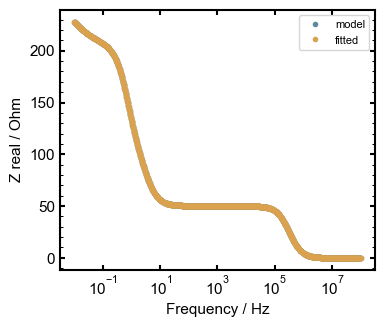

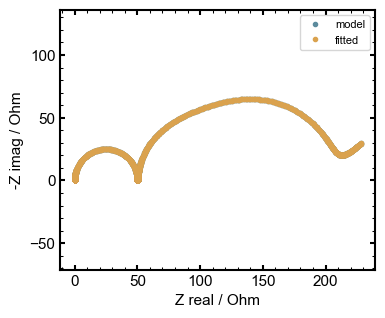

In [14]:
### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('R1', value=80.0, max=100, min=0.0)
FitParameters.add('C1', value=20.0E-9, max=10.0E-8, min=10.0E-10)
FitParameters.add('R2', value=30.0, max=100, min=0.0)
FitParameters.add('C2', value=30.0E-4, max=10.0E-3, min=10.0E-5)
FitParameters.add('R3', value=400.0, max=200, min=0.0)
FitParameters.add('C3', value=3.2E-3, max=2.2E-4, min=2.2E-2)
FitParameters.add('Q1', value=3.0E-1, max=1.0, min=1.0E-2)
FitParameters.add('n1', value=0.7, max=1.0, min=0.3)

#print(Fit_Zabs_RCRCRCCPE(fit_params, f, Z_abs_messung))

# Searches the minimum of the residual function
result_optimization = minimize(fcn=Fit_Z_Real_Imag_RCRCRCCPE, params=FitParameters,  args=(f,Z_real_imag_measurement), method='nelder')


########## Plot the optimised values and the model values for comparison
# Calculate the Z values with the optimised parameters (given in 'out.params')
Z_from_optimized_parameters = Fit_Z_Real_Imag_RCRCRCCPE(result_optimization.params, f, Z_real_imag_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RC_Model(f, ModelValuesRCRCRCCPE, PhaseAngle=False)

#print(result_optimization.params)

Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [15]:
report_fit(result_optimization, show_correl=False, modelpars=ModelParameters)

[[Fit Statistics]]
    # fitting method   = Nelder-Mead
    # function evals   = 2751
    # data points      = 2000
    # variables        = 8
    chi-square         = 2.9579e-05
    reduced chi-square = 1.4849e-08
    Akaike info crit   = -36042.6881
    Bayesian info crit = -35997.8808
[[Variables]]
    R1:  50.0000721 +/- 6.0398e-06 (0.00%) (init = 80), model_value = 50
    C1:  1.0000e-08 +/- 5.2326e-15 (0.00%) (init = 2e-08), model_value = 1e-08
    R2:  50.0026095 +/- 8.7054e-05 (0.00%) (init = 30), model_value = 50
    C2:  9.9997e-04 +/- 8.6135e-10 (0.00%) (init = 0.003), model_value = 0.001
    R3:  99.9985091 +/- 8.0170e-05 (0.00%) (init = 200), model_value = 100
    C3:  0.00220010 +/- 3.4260e-09 (0.00%) (init = 0.0032), model_value = 0.0022
    Q1:  0.10000839 +/- 2.8114e-07 (0.00%) (init = 0.3), model_value = 0.1
    n1:  0.50002383 +/- 7.8044e-07 (0.00%) (init = 0.7), model_value = 0.5


In [16]:
################################### Optimisation with the brute method (grid search) ####################################

In [17]:
#In a more realistic, complicated example the brute method will be used to get reasonable values for the 
#parameters and perform another minimization (e.g., using leastsq) using those as starting values. 
#That is where the keep` parameter comes into play: it determines the “number of best candidates from the 
#brute force method that are stored in the candidates attribute”. In the example above we store the 
#best-ranking 25 solutions (the default value is 50 and storing all the grid points can be accomplished 
#by choosing all). The candidates attribute contains the parameters and 
#chisqr from the brute force method as a namedtuple, (‘Candidate’, [‘params’, ‘score’]), sorted 
#on the (lowest) chisqr value. To access the values for a particular candidate one can use 
#result.candidate[#].params or result.candidate[#].score, where a lower # represents a better 
#candidate. The show_candidates(#) uses the pretty_print() method to show a specific 
#candidate-# or all candidates when no number is specified.

(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

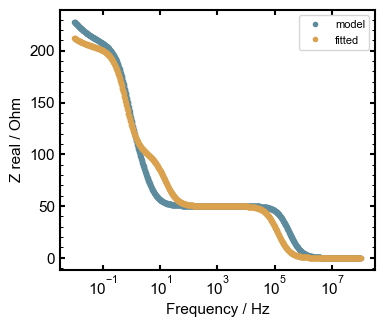

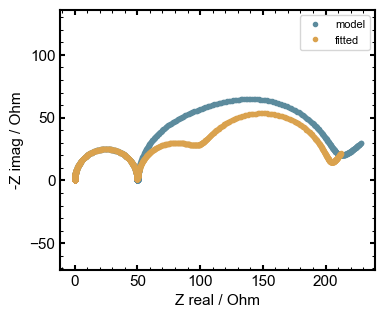

In [18]:
### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('R1', value=80.0, max=100, min=0.0)
FitParameters.add('C1', value=20.0E-9, max=10.0E-8, min=10.0E-10)
FitParameters.add('R2', value=30.0, max=100, min=0.0)
FitParameters.add('C2', value=30.0E-4, max=10.0E-3, min=10.0E-5)
FitParameters.add('R3', value=400.0, max=200, min=0.0)
FitParameters.add('C3', value=3.2E-3, max=2.2E-4, min=2.2E-2)
FitParameters.add('Q1', value=3.0E-1, max=1.0, min=1.0E-2)
FitParameters.add('n1', value=0.7, max=1.0, min=0.3)

#print(Fit_Zabs_RCRCRCCPE(fit_params, f, Z_abs_messung))

# Searches the minimum of the residual function
result_optimization = minimize(fcn=Fit_Z_Real_Imag_RCRCRCCPE, params=FitParameters,  args=(f,Z_real_imag_measurement), method='brute', Ns=5, keep=10) # "Ns" = grid steps for the axes, "keep" = how many optimized parameter sets should be saved for later use


########## Plot the optimised values and the model values for comparison
# Calculate the Z values with the optimised parameters (given in 'out.params')
Z_from_optimized_parameters = Fit_Z_Real_Imag_RCRCRCCPE(result_optimization.params, f, Z_real_imag_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RC_Model(f, ModelValuesRCRCRCCPE, PhaseAngle=False)

#print(result_optimization.params)

Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [19]:
report_fit(result_optimization, show_correl=True, modelpars=ModelParameters)

[[Fit Statistics]]
    # fitting method   = brute
    # function evals   = 390625
    # data points      = 2000
    # variables        = 8
    chi-square         = 171878.284
    reduced chi-square = 86.2842791
    Akaike info crit   = 8923.27879
    Bayesian info crit = 8968.08601
##  Warning: uncertainties could not be estimated:
    C1:  at initial value
    R2:  at boundary
    C3:  at boundary
[[Variables]]
    R1:  50.0000000 (init = 80), model_value = 50
    C1:  2.5750e-08 (init = 2e-08), model_value = 1e-08
    R2:  100.000000 (init = 30), model_value = 50
    C2:  0.00257500 (init = 0.003), model_value = 0.001
    R3:  50.0000000 (init = 400), model_value = 100
    C3:  2.2000e-04 (init = 0.0032), model_value = 0.0022
    Q1:  0.25750000 (init = 0.3), model_value = 0.1
    n1:  0.65000000 (init = 0.7), model_value = 0.5


In [20]:
result_optimization.show_candidates(1) # Shows the best parameters from the brute grid search method/minimization
result_optimization.show_candidates(2) # Shows the second best parameters from the brute grid search method/minimization


Candidate #1, chisqr = 171878.284
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
C1  2.575e-08    1e-09    1e-07     None     True     None     None
C2  0.002575   0.0001     0.01     None     True     None     None
C3   0.00022  0.00022    0.022     None     True     None     None
Q1    0.2575     0.01        1     None     True     None     None
R1        50        0      100     None     True     None     None
R2       100        0      100     None     True     None     None
R3        50        0      200     None     True     None     None
n1      0.65      0.3        1     None     True     None     None

Candidate #2, chisqr = 173953.687
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
C1  2.575e-08    1e-09    1e-07     None     True     None     None
C2  0.002575   0.0001     0.01     None     True     None     None
C3   0.00022  0.00022    0.022     None     True     None     None
Q1    0.2575     0.01        1     None     True 

In [21]:
########## The best parameters (lowest chisqr) of the brute method are optimised again with the leastsq method and compared with the chisqr of the brute method alone
# -> if the least squares optimisation gives a better result, the variable "best_result" is overwritten
best_result = copy.deepcopy(result_optimization)

for candidate in result_optimization.candidates: 
    trial = minimize(fcn=Fit_Z_Real_Imag_RCRCRCCPE, params=candidate.params,  args=(f,Z_real_imag_measurement), method='leastsq')
    if trial.chisqr < best_result.chisqr: # Comparison of chisqr between the previous "best_result" and the newly calculated "trial"
        best_result = trial


# Calculate the Z values with the best parameters
Z_from_optimized_parameters = Fit_Z_Real_Imag_RCRCRCCPE(best_result.params, f, Z_real_imag_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RC_Model(f, ModelValuesRCRCRCCPE, PhaseAngle=False)        


In [22]:
print(fit_report(best_result))

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 401
    # data points      = 2000
    # variables        = 8
    chi-square         = 3.0304e-17
    reduced chi-square = 1.5213e-20
    Akaike info crit   = -91256.2983
    Bayesian info crit = -91211.4911
##  Warning: uncertainties could not be estimated:
    R1:  at initial value
    C1:  at boundary
    R2:  at initial value
    R2:  at boundary
    R3:  at initial value
[[Variables]]
    R1:  50.0000000 (init = 50)
    C1:  1.0000e-08 (init = 2.575e-08)
    R2: 100.0000000 (init = 100)
    C2:  0.00220000 (init = 0.002575)
    R3:  50.0000000 (init = 50)
    C3:  1.0000e-03 (init = 0.00022)
    Q1:  0.10000000 (init = 0.505)
    n1:  0.50000000 (init = 0.825)


(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

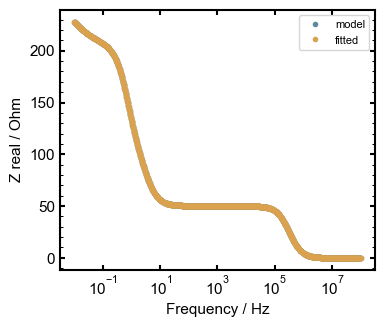

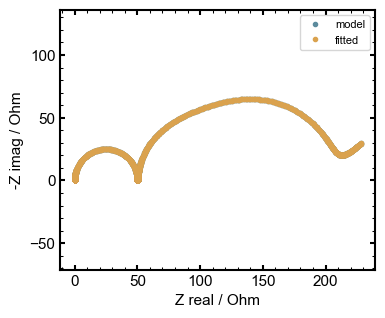

In [23]:
# Comparison of the model and the best fit
Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [24]:
############################### Fit B: RQ-RQ-RQ-CPE model, fitted to the real and imaginary part ####################

In [25]:
############ Define the Function for Fitting and the Parameters ##############

### Values of the function for simulating the data (only needed if the function is simulated again)
ModelParameters = Parameters() # Parameters is a function of the lmfit package
ModelParameters.add('R1', value=ModelValuesRQRQRQCPE[0]) # The above definde Parameters of the Model ('ModelValuesRCRCRCCPE') are also defiend for the Parameters() function
ModelParameters.add('Q1', value=ModelValuesRQRQRQCPE[1])
ModelParameters.add('n1', value=ModelValuesRQRQRQCPE[2])
ModelParameters.add('R2', value=ModelValuesRQRQRQCPE[3]) 
ModelParameters.add('Q2', value=ModelValuesRQRQRQCPE[4])
ModelParameters.add('n2', value=ModelValuesRQRQRQCPE[5])
ModelParameters.add('R3', value=ModelValuesRQRQRQCPE[6]) 
ModelParameters.add('Q3', value=ModelValuesRQRQRQCPE[7])
ModelParameters.add('n3', value=ModelValuesRQRQRQCPE[8])
ModelParameters.add('Q4', value=ModelValuesRQRQRQCPE[9])
ModelParameters.add('n4', value=ModelValuesRQRQRQCPE[10])

f = np.logspace(-2, 8, 1000)

Z_real_imag_measurement = np.append(Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False).real, Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False).imag)

#print(len(Z_real_imag))

In [26]:
############################ Fitting with the 'nelder' method ######################

(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

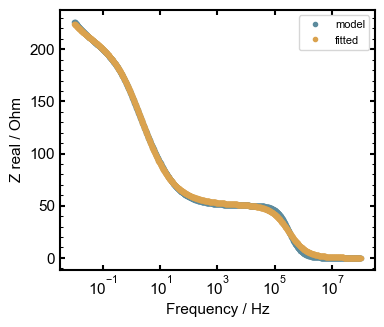

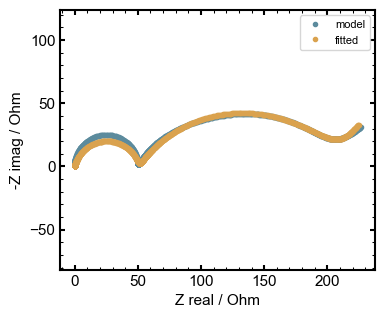

In [27]:
### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('R1', value=80.0, max=100, min=0.0)
FitParameters.add('Q1', value=20.0E-9, max=10.0E-8, min=10.0E-10)
FitParameters.add('n1', value=0.7, max=1.0, min=0.3)
FitParameters.add('R2', value=30.0, max=100, min=0.0)
FitParameters.add('Q2', value=30.0E-4, max=10.0E-3, min=10.0E-5)
FitParameters.add('n2', value=0.3, max=1.0, min=0.3)
FitParameters.add('R3', value=400.0, max=200, min=0.0)
FitParameters.add('Q3', value=3.2E-3, max=2.2E-4, min=2.2E-2)
FitParameters.add('n3', value=0.1, max=1.0, min=0.3)
FitParameters.add('Q4', value=3.0E-1, max=1.0, min=1.0E-2)
FitParameters.add('n4', value=0.7, max=1.0, min=0.3)

#print(Fit_Zabs_RCRCRCCPE(fit_params, f, Z_abs_messung))

# Searches the minimum of the residual function
result_optimization = minimize(fcn=Fit_Z_Real_Imag_RQRQRQCPE, params=FitParameters,  args=(f,Z_real_imag_measurement), method='nelder')


########## Plot the optimised values and the model values for comparison
# Calculate the Z values with the optimised parameters (given in 'out.params')
Z_from_optimized_parameters = Fit_Z_Real_Imag_RQRQRQCPE(result_optimization.params, f, Z_real_imag_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False)

#print(result_optimization.params)

Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [28]:
report_fit(result_optimization, show_correl=False, modelpars=ModelParameters)

[[Fit Statistics]]
    # fitting method   = Nelder-Mead
    # function evals   = 1980
    # data points      = 2000
    # variables        = 11
    chi-square         = 4250.52117
    reduced chi-square = 2.13701416
    Akaike info crit   = 1529.78885
    Bayesian info crit = 1591.39877
##  Warning: uncertainties could not be estimated:
    Q1:  at boundary
[[Variables]]
    R1:  50.7132335 (init = 80), model_value = 50
    Q1:  9.2975e-08 (init = 2e-08), model_value = 1e-08
    n1:  0.84801453 (init = 0.7), model_value = 1
    R2:  3.04989580 (init = 30), model_value = 50
    Q2:  0.00879131 (init = 0.003), model_value = 0.001
    n2:  0.83901312 (init = 0.3), model_value = 0.7
    R3:  157.056949 (init = 200), model_value = 100
    Q3:  0.00127971 (init = 0.0032), model_value = 0.0022
    n3:  0.60997019 (init = 0.3), model_value = 0.7
    Q4:  0.18317531 (init = 0.3), model_value = 0.1
    n4:  0.65454135 (init = 0.7), model_value = 0.5


In [29]:
################################### Optimisation with the brute method (grid search) ####################################

(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

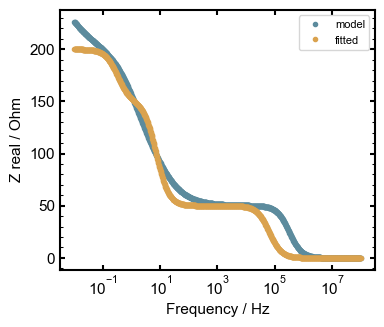

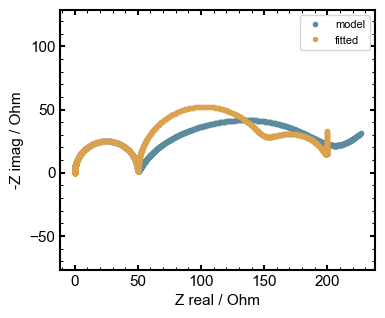

In [30]:
### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('R1', value=80.0, max=100, min=0.0)
FitParameters.add('Q1', value=20.0E-9, max=10.0E-8, min=10.0E-10)
FitParameters.add('n1', value=0.7, max=1.0, min=0.3)
FitParameters.add('R2', value=30.0, max=100, min=0.0)
FitParameters.add('Q2', value=30.0E-4, max=10.0E-3, min=10.0E-5)
FitParameters.add('n2', value=0.3, max=1.0, min=0.3)
FitParameters.add('R3', value=400.0, max=200, min=0.0)
FitParameters.add('Q3', value=3.2E-3, max=2.2E-4, min=2.2E-2)
FitParameters.add('n3', value=0.1, max=1.0, min=0.3)
FitParameters.add('Q4', value=3.0E-1, max=1.0, min=1.0E-2)
FitParameters.add('n4', value=0.7, max=1.0, min=0.3)

#print(Fit_Zabs_RCRCRCCPE(fit_params, f, Z_abs_messung))

# Searches the minimum of the residual function
result_optimization = minimize(fcn=Fit_Z_Real_Imag_RQRQRQCPE, params=FitParameters,  args=(f,Z_real_imag_measurement), method='brute', Ns=3, keep=10) # "Ns" = grid steps for the axes (3 instead of 5: with 5 steps the 11 parameters need 48 million evaluations, which is more than lmfit allows), "keep" = how many optimized parameter sets should be saved for later use


########## Plot the optimised values and the model values for comparison
# Calculate the Z values with the optimised parameters (given in 'out.params')
Z_from_optimized_parameters = Fit_Z_Real_Imag_RQRQRQCPE(result_optimization.params, f, Z_real_imag_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False)

#print(result_optimization.params)

Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [31]:
report_fit(result_optimization, show_correl=True, modelpars=ModelParameters)

[[Fit Statistics]]
    # fitting method   = brute
    # function evals   = 177147
    # data points      = 2000
    # variables        = 11
    chi-square         = 194005.733
    reduced chi-square = 97.5393330
    Akaike info crit   = 9171.48106
    Bayesian info crit = 9233.09099
##  Warning: uncertainties could not be estimated:
    n1:  at boundary
    Q2:  at boundary
    n2:  at boundary
    Q3:  at boundary
    n3:  at boundary
    n4:  at boundary
[[Variables]]
    R1:  50.0000000 (init = 80), model_value = 50
    Q1:  5.0500e-08 (init = 2e-08), model_value = 1e-08
    n1:  1.00000000 (init = 0.7), model_value = 1
    R2:  50.0000000 (init = 30), model_value = 50
    Q2:  0.01000000 (init = 0.003), model_value = 0.001
    n2:  1.00000000 (init = 0.3), model_value = 0.7
    R3:  100.000000 (init = 400), model_value = 100
    Q3:  2.2000e-04 (init = 0.0032), model_value = 0.0022
    n3:  1.00000000 (init = 0.1), model_value = 0.7
    Q4:  0.50500000 (init = 0.3), model_value = 0

In [32]:
result_optimization.show_candidates(1) # Shows the best parameters from the brute grid search method/minimization
result_optimization.show_candidates(2) # Shows the second best parameters from the brute grid search method/minimization


Candidate #1, chisqr = 194005.733
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
Q1  5.05e-08    1e-09    1e-07     None     True     None     None
Q2      0.01   0.0001     0.01     None     True     None     None
Q3   0.00022  0.00022    0.022     None     True     None     None
Q4     0.505     0.01        1     None     True     None     None
R1        50        0      100     None     True     None     None
R2        50        0      100     None     True     None     None
R3       100        0      200     None     True     None     None
n1         1      0.3        1     None     True     None     None
n2         1      0.3        1     None     True     None     None
n3         1      0.3        1     None     True     None     None
n4         1      0.3        1     None     True     None     None

Candidate #2, chisqr = 197429.922
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
Q1  5.05e-08    1e-09    1e-07     None     True   

In [33]:
########## The best parameters (lowest chisqr) of the brute method are optimised again with the leastsq method and compared with the chisqr of the brute method alone
# -> if the least squares optimisation gives a better result, the variable "best_result" is overwritten
best_result = copy.deepcopy(result_optimization)

for candidate in result_optimization.candidates: 
    trial = minimize(fcn=Fit_Z_Real_Imag_RQRQRQCPE, params=candidate.params,  args=(f,Z_real_imag_measurement), method='leastsq')
    if trial.chisqr < best_result.chisqr: # Comparison of chisqr between the previous "best_result" and the newly calculated "trial"
        best_result = trial


# Calculate the Z values with the best parameters
Z_from_optimized_parameters = Fit_Z_Real_Imag_RQRQRQCPE(best_result.params, f, Z_real_imag_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False)        


In [34]:
print(fit_report(best_result))

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 4277
    # data points      = 2000
    # variables        = 11
    chi-square         = 7.3160e-17
    reduced chi-square = 3.6782e-20
    Akaike info crit   = -89487.5649
    Bayesian info crit = -89425.9550
##  Warning: uncertainties could not be estimated:
    R1:  at initial value
    Q1:  at boundary
    n1:  at initial value
    n1:  at boundary
    R2:  at boundary
[[Variables]]
    R1:  50.0000000 (init = 50)
    Q1:  1.0000e-08 (init = 5.05e-08)
    n1:  1.00000000 (init = 1)
    R2: 100.0000000 (init = 50)
    Q2:  0.00220000 (init = 0.00505)
    n2:  0.70000000 (init = 1)
    R3:  50.0000000 (init = 100)
    Q3:  1.0000e-03 (init = 0.00022)
    n3:  0.70000000 (init = 1)
    Q4:  0.10000000 (init = 0.505)
    n4:  0.50000000 (init = 1)


(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

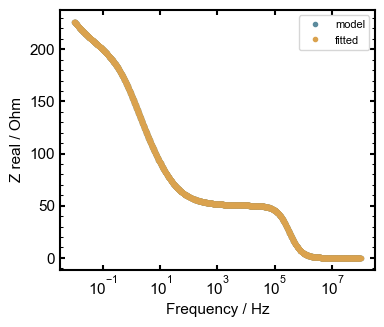

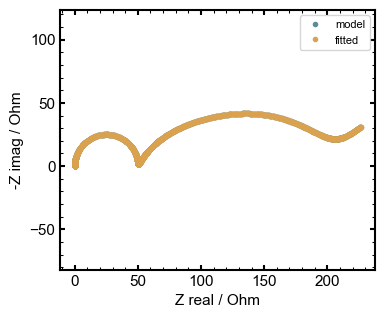

In [35]:
# Comparison of the model and the best fit
Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [36]:
############################### Fit C: RQ-RQ-RQ-CPE model, fitted to the real part, imaginary part and phase angle, start values from an initial guess ####################

In [37]:
############ Define the Function for Fitting and the Parameters ##############

### Values of the function for simulating the data (only needed if the function is simulated again)
ModelParameters = Parameters() # Parameters is a function of the lmfit package
ModelParameters.add('R1', value=ModelValuesRQRQRQCPE[0]) # The above definde Parameters of the Model ('ModelValuesRCRCRCCPE') are also defiend for the Parameters() function
ModelParameters.add('Q1', value=ModelValuesRQRQRQCPE[1])
ModelParameters.add('n1', value=ModelValuesRQRQRQCPE[2])
ModelParameters.add('R2', value=ModelValuesRQRQRQCPE[3]) 
ModelParameters.add('Q2', value=ModelValuesRQRQRQCPE[4])
ModelParameters.add('n2', value=ModelValuesRQRQRQCPE[5])
ModelParameters.add('R3', value=ModelValuesRQRQRQCPE[6]) 
ModelParameters.add('Q3', value=ModelValuesRQRQRQCPE[7])
ModelParameters.add('n3', value=ModelValuesRQRQRQCPE[8])
ModelParameters.add('Q4', value=ModelValuesRQRQRQCPE[9])
ModelParameters.add('n4', value=ModelValuesRQRQRQCPE[10])

f = np.logspace(-2, 8, 2000)

#Z_real_imag_phaseangle_measurement = np.append(Impedance(f, ModelValuesRQRQRQCPE, PhaseAngle=False).real, Impedance(f, ModelValuesRQRQRQCPE, PhaseAngle=False).imag, Impedance(f, ModelValuesRQRQRQCPE, PhaseAngle=True))
Z_real_imag_phaseangle_measurement = np.concatenate([Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False).real, Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False).imag, Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=True)])

#print(len(Z_real_imag))

In [38]:
############################ Fitting with the 'nelder' method ######################

(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

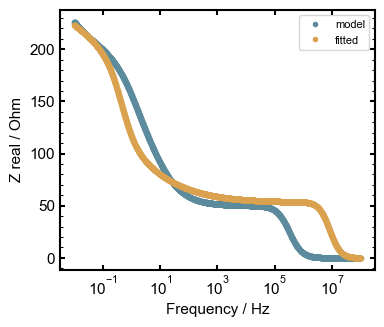

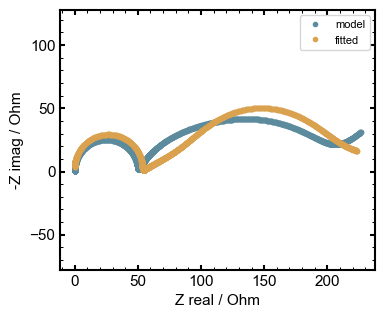

In [39]:
### Start values for the optimisation and their limits
R1_guessed = 60
Q1_guessed = 1.0E-10
n1_guessed = 0.8
R2_guessed = 70
Q2_guessed = 5.0E-3
n2_guessed = 0.9
R3_guessed = 120
Q3_guessed = 5.0E-3
n3_guessed = 0.9
Q4_guessed = 6.0E-1
n4_guessed = 0.4

R1_limits = [R1_guessed + R1_guessed*0.60 , R1_guessed - R1_guessed*0.60]
Q1_limits = [Q1_guessed + Q1_guessed*0.60 , Q1_guessed - Q1_guessed*0.60]
n1_limits = [n1_guessed + n1_guessed*0.60 , n1_guessed - n1_guessed*0.60]
R2_limits = [R2_guessed + R2_guessed*0.60 , R2_guessed - R2_guessed*0.60]
Q2_limits = [Q2_guessed + Q2_guessed*0.60 , Q2_guessed - Q2_guessed*0.60]
n2_limits = [n2_guessed + n2_guessed*0.60 , n2_guessed - n2_guessed*0.60]
R3_limits = [R3_guessed + R3_guessed*0.60 , R3_guessed - R3_guessed*0.60]
Q3_limits = [Q3_guessed + Q3_guessed*0.60 , Q3_guessed - Q3_guessed*0.60]
n3_limits = [n3_guessed + n3_guessed*0.60 , n3_guessed - n3_guessed*0.60]
Q4_limits = [Q4_guessed + Q4_guessed*0.60 , Q4_guessed - Q4_guessed*0.60]
n4_limits = [n4_guessed + n4_guessed*0.60 , n4_guessed - n4_guessed*0.60]

FitParameters = Parameters()
FitParameters.add('R1', value=R1_guessed, max=R1_limits[0], min=R1_limits[1])
FitParameters.add('Q1', value=Q1_guessed, max=Q1_limits[0], min=Q1_limits[1])
FitParameters.add('n1', value=n1_guessed, max=n1_limits[0], min=n1_limits[1])
FitParameters.add('R2', value=R2_guessed, max=R2_limits[0], min=R2_limits[1])
FitParameters.add('Q2', value=Q2_guessed, max=Q2_limits[0], min=Q2_limits[1])
FitParameters.add('n2', value=n2_guessed, max=n2_limits[0], min=n2_limits[1])
FitParameters.add('R3', value=R3_guessed, max=R3_limits[0], min=R3_limits[1])
FitParameters.add('Q3', value=Q3_guessed, max=Q3_limits[0], min=Q3_limits[1])
FitParameters.add('n3', value=n3_guessed, max=n3_limits[0], min=n3_limits[1])
FitParameters.add('Q4', value=Q4_guessed, max=Q4_limits[0], min=Q4_limits[1])
FitParameters.add('n4', value=n4_guessed, max=n4_limits[0], min=n4_limits[1])

#print(Fit_Zabs_RCRCRCCPE(fit_params, f, Z_abs_messung))

# Searches the minimum of the residual function
result_optimization = minimize(fcn=Fit_Z_Real_Imag_Phase_RQRQRQCPE, params=FitParameters,  args=(f,Z_real_imag_phaseangle_measurement), method='nelder', max_nfev=10000)


########## Plot the optimised values and the model values for comparison
# Calculate the Z values with the optimised parameters (given in 'out.params')
Z_from_optimized_parameters = Fit_Z_Real_Imag_Phase_RQRQRQCPE(result_optimization.params, f, Z_real_imag_phaseangle_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False)

#print(result_optimization.params)

Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [40]:
report_fit(result_optimization, show_correl=False, modelpars=ModelParameters)

[[Fit Statistics]]
    # fitting method   = Nelder-Mead
    # function evals   = 7243
    # data points      = 6000
    # variables        = 11
    chi-square         = 2438581.50
    reduced chi-square = 407.176740
    Akaike info crit   = 36066.4740
    Bayesian info crit = 36140.1686
[[Variables]]
    R1:  53.0036688 +/- 0.00112249 (0.00%) (init = 60), model_value = 50
    Q1:  1.2394e-10 +/- 1.7487e-15 (0.00%) (init = 1e-10), model_value = 1e-08
    n1:  1.06057828 +/- 1.2814e-05 (0.00%) (init = 0.8), model_value = 1
    R2:  70.5952817 +/- 1.19564001 (1.69%) (init = 70), model_value = 50
    Q2:  0.00535933 +/- 9.4673e-08 (0.00%) (init = 0.005), model_value = 0.001
    n2:  0.94331263 +/- 1.7109e-05 (0.00%) (init = 0.9), model_value = 0.7
    R3:  117.857307 +/- 0.00228761 (0.00%) (init = 120), model_value = 100
    Q3:  0.00601642 +/- 8.9719e-08 (0.00%) (init = 0.005), model_value = 0.0022
    n3:  0.36230216 +/- 1.5833e-06 (0.00%) (init = 0.9), model_value = 0.7
    Q4:  0.56939

In [41]:
################################### Optimisation with the brute method (grid search) ####################################

(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

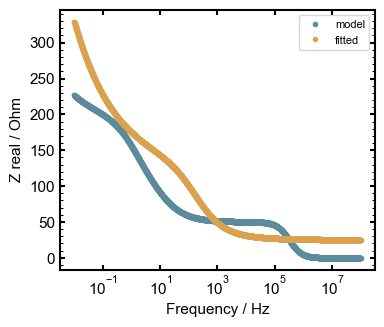

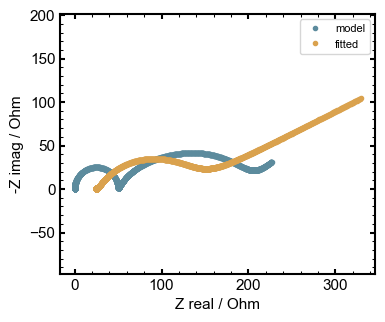

In [42]:
### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('R1', value=25, max=80, min=25.0, brute_step=5)
FitParameters.add('Q1', value=10.0E-10, max=10.0E-8, min=10.0E-10, brute_step=5)
FitParameters.add('n1', value=0.7, max=1.0, min=0.7, brute_step=5)
FitParameters.add('R2', value=50.0, max=100, min=50, brute_step=5)
FitParameters.add('Q2', value=10.0E-5, max=10.0E-3, min=10.0E-5, brute_step=5)
FitParameters.add('n2', value=0.7, max=1.0, min=0.7, brute_step=5)
FitParameters.add('R3', value=50.0, max=100, min=50.0, brute_step=5)
FitParameters.add('Q3', value=2.2E-2, max=2.2E-4, min=2.2E-2, brute_step=5)
FitParameters.add('n3', value=0.7, max=1.0, min=0.7, brute_step=5)
FitParameters.add('Q4', value=1.0E-2, max=1.0, min=1.0E-2, brute_step=5)
FitParameters.add('n4', value=0.3, max=0.7, min=0.3, brute_step=5)

#FitParameters.add('R1', value=0, max=300, min=00.0, brute_step=5)
#FitParameters.add('Q1', value=1.0E-10, max=1.0, min=1.0E-10, brute_step=5)
#FitParameters.add('n1', value=0.6, max=1.0, min=0.6, brute_step=5)
#FitParameters.add('R2', value=00.0, max=300, min=0, brute_step=5)
#FitParameters.add('Q2', value=1.0E-10, max=1.0, min=1.0E-10, brute_step=5)
#FitParameters.add('n2', value=0.6, max=1.0, min=0.6, brute_step=5)
#FitParameters.add('R3', value=0.0, max=300, min=0.0, brute_step=5)
#FitParameters.add('Q3', value=1.0E-10, max=1.0, min=1.0E-10, brute_step=5)
#FitParameters.add('n3', value=0.6, max=1.0, min=0.6, brute_step=5)
#FitParameters.add('Q4', value=1.0E-10, max=1.0, min=1.0E-10, brute_step=5)
#FitParameters.add('n4', value=0.3, max=0.7, min=0.3, brute_step=5)

#R1_guessed = 60
#Q1_guessed = 1.0E-10
#n1_guessed = 0.8
#R2_guessed = 70
#Q2_guessed = 5.0E-3
#n2_guessed = 0.9
#R3_guessed = 120
#Q3_guessed = 5.0E-3
#n3_guessed = 0.9
#Q4_guessed = 6.0E-1
#n4_guessed = 0.4

#R1_limits = [R1_guessed + R1_guessed*0.60 , R1_guessed - R1_guessed*0.60]
#Q1_limits = [Q1_guessed + Q1_guessed*3.60 , Q1_guessed - Q1_guessed*3.60]
#n1_limits = [n1_guessed + n1_guessed*0.60 , n1_guessed - n1_guessed*0.60]
#R2_limits = [R2_guessed + R2_guessed*0.60 , R2_guessed - R2_guessed*0.60]
#Q2_limits = [Q2_guessed + Q2_guessed*3.60 , Q2_guessed - Q2_guessed*3.60]
#n2_limits = [n2_guessed + n2_guessed*0.60 , n2_guessed - n2_guessed*0.60]
#R3_limits = [R3_guessed + R3_guessed*0.60 , R3_guessed - R3_guessed*0.60]
#Q3_limits = [Q3_guessed + Q3_guessed*3.60 , Q3_guessed - Q3_guessed*3.60]
#n3_limits = [n3_guessed + n3_guessed*0.60 , n3_guessed - n3_guessed*0.60]
#Q4_limits = [Q4_guessed + Q4_guessed*0.60 , Q4_guessed - Q4_guessed*0.60]
#n4_limits = [n4_guessed + n4_guessed*3.60 , n4_guessed - n4_guessed*3.60]

#FitParameters = Parameters()
#FitParameters.add('R1', value=R1_guessed, max=R1_limits[0], min=R1_limits[1], brute_step=5)
#FitParameters.add('Q1', value=Q1_guessed, max=Q1_limits[0], min=Q1_limits[1], brute_step=5)
#FitParameters.add('n1', value=n1_guessed, max=n1_limits[0], min=n1_limits[1], brute_step=5)
#FitParameters.add('R2', value=R2_guessed, max=R2_limits[0], min=R2_limits[1], brute_step=5)
#FitParameters.add('Q2', value=Q2_guessed, max=Q2_limits[0], min=Q2_limits[1], brute_step=5)
#FitParameters.add('n2', value=n2_guessed, max=n2_limits[0], min=n2_limits[1], brute_step=5)
#FitParameters.add('R3', value=R3_guessed, max=R3_limits[0], min=R3_limits[1], brute_step=5)
#FitParameters.add('Q3', value=Q3_guessed, max=Q3_limits[0], min=Q3_limits[1], brute_step=5)
#FitParameters.add('n3', value=n3_guessed, max=n3_limits[0], min=n3_limits[1], brute_step=5)
#FitParameters.add('Q4', value=Q4_guessed, max=Q4_limits[0], min=Q4_limits[1], brute_step=5)
#FitParameters.add('n4', value=n4_guessed, max=n4_limits[0], min=n4_limits[1], brute_step=5)

#print(Fit_Zabs_RCRCRCCPE(fit_params, f, Z_abs_messung))

# Searches the minimum of the residual function
result_optimization = minimize(fcn=Fit_Z_Real_Imag_Phase_RQRQRQCPE, params=FitParameters,  args=(f,Z_real_imag_phaseangle_measurement), method='brute', Ns=5, keep=10) # "Ns" = grid steps for the axes, "keep" = how many optimized parameter sets should be saved for later use


########## Plot the optimised values and the model values for comparison
# Calculate the Z values with the optimised parameters (given in 'out.params')
Z_from_optimized_parameters = Fit_Z_Real_Imag_Phase_RQRQRQCPE(result_optimization.params, f, Z_real_imag_phaseangle_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False)

#print(result_optimization.params)

Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)

In [43]:
report_fit(result_optimization, show_correl=True, modelpars=ModelParameters)

[[Fit Statistics]]
    # fitting method   = brute
    # function evals   = 1100
    # data points      = 6000
    # variables        = 11
    chi-square         = 6622171.20
    reduced chi-square = 1105.72236
    Akaike info crit   = 42060.5146
    Bayesian info crit = 42134.2093
##  Warning: uncertainties could not be estimated:
    R1:  at initial value
    R1:  at boundary
    Q1:  at initial value
    Q1:  at boundary
    n1:  at initial value
    n1:  at boundary
    R2:  at initial value
    R2:  at boundary
    Q2:  at initial value
    Q2:  at boundary
    n2:  at initial value
    n2:  at boundary
    R3:  at initial value
    R3:  at boundary
    Q3:  at boundary
    n3:  at initial value
    n3:  at boundary
    Q4:  at initial value
    Q4:  at boundary
    n4:  at initial value
    n4:  at boundary
[[Variables]]
    R1:  25.0000000 (init = 25), model_value = 50
    Q1:  1.0000e-09 (init = 1e-09), model_value = 1e-08
    n1:  0.70000000 (init = 0.7), model_value = 1
    R2

In [44]:
result_optimization.show_candidates(1) # Shows the best parameters from the brute grid search method/minimization
result_optimization.show_candidates(2) # Shows the second best parameters from the brute grid search method/minimization


Candidate #1, chisqr = 6622171.199
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
Q1     1e-09    1e-09    1e-07     None     True     None        5
Q2    0.0001   0.0001     0.01     None     True     None        5
Q3   0.00022  0.00022    0.022     None     True     None        5
Q4      0.01     0.01        1     None     True     None        5
R1        25       25       80     None     True     None        5
R2        50       50      100     None     True     None        5
R3        50       50      100     None     True     None        5
n1       0.7      0.7        1     None     True     None        5
n2       0.7      0.7        1     None     True     None        5
n3       0.7      0.7        1     None     True     None        5
n4       0.3      0.3      0.7     None     True     None        5

Candidate #2, chisqr = 6916172.537
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
Q1     1e-09    1e-09    1e-07     None     True 

In [45]:
########## The best parameters (lowest chisqr) of the brute method are optimised again with the leastsq method and compared with the chisqr of the brute method alone
# -> if the least squares optimisation gives a better result, the variable "best_result" is overwritten
best_result = copy.deepcopy(result_optimization)

for candidate in result_optimization.candidates: 
    trial = minimize(fcn=Fit_Z_Real_Imag_Phase_RQRQRQCPE, params=candidate.params,  args=(f,Z_real_imag_phaseangle_measurement), method='nelder') #'leastsq'
    if trial.chisqr < best_result.chisqr: # Comparison of chisqr between the previous "best_result" and the newly calculated "trial"
        best_result = trial


# Calculate the Z values with the best parameters
Z_from_optimized_parameters = Fit_Z_Real_Imag_Phase_RQRQRQCPE(best_result.params, f, Z_real_imag_phaseangle_measurement=None)
# Calculation of the Z values of the model
Z_from_model = Calculate_Impedance_RQ_Model(f, ModelValuesRQRQRQCPE, PhaseAngle=False)        


In [46]:
print(fit_report(best_result, show_correl=True, modelpars=ModelParameters))

[[Fit Statistics]]
    # fitting method   = Nelder-Mead
    # function evals   = 8032
    # data points      = 6000
    # variables        = 11
    chi-square         = 23.5277491
    reduced chi-square = 0.00392849
    Akaike info crit   = -33226.0053
    Bayesian info crit = -33152.3106
[[Variables]]
    R1:  50.0436811 +/- 0.00242529 (0.00%) (init = 30), model_value = 50
    Q1:  9.9993e-09 +/- 1.9218e-12 (0.02%) (init = 1e-09), model_value = 1e-08
    n1:  0.99998784 +/- 9.1408e-06 (0.00%) (init = 0.7), model_value = 1
    R2:  61.5834545 +/- 0.13106205 (0.21%) (init = 50), model_value = 50
    Q2:  8.8783e-04 +/- 9.7082e-07 (0.11%) (init = 0.0001), model_value = 0.001
    n2:  0.70000732 +/- 6.6043e-06 (0.00%) (init = 0.7), model_value = 0.7
    R3:  84.9751136 +/- 0.16796316 (0.20%) (init = 55), model_value = 100
    Q3:  0.00262391 +/- 5.7973e-06 (0.22%) (init = 0.00022), model_value = 0.0022
    n3:  0.73682376 +/- 4.7341e-04 (0.06%) (init = 0.7), model_value = 0.7
    Q4:  0.0

(<Figure size 314.961x433.071 with 1 Axes>,
 <Figure size 314.961x433.071 with 1 Axes>)

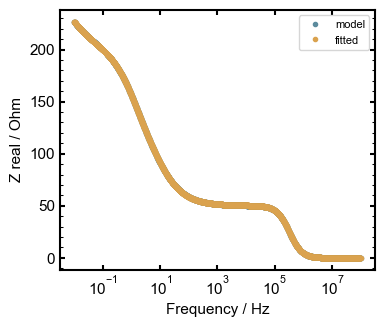

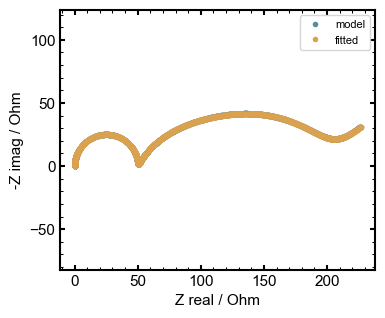

In [47]:
# Comparison of the model and the best fit
Matplotlib_Compare_Model_And_Fit(f, Z_from_model, Z_from_optimized_parameters)